In [17]:
# napisane kodu do tworzenia histogramu na podstawie matplotlib
import matplotlib.pyplot as plt
import numpy as np
from typing import Counter
# funkcja pomocnicza ktora recordowi przypisze numer koszyka(bucket) na podstawie ustalonej wartosci bucket_size oznaczajacej szerokosc zakresu

def bucketize(point:float, bucket_size:float) -> float:

    return bucket_size * np.floor(point/bucket_size).item() 

assert bucketize(15,10) == 10

def make_histogram(list_of_points:list, bucket_size:float):
    'tworzy slownik gdzie klucze to przedzialy koszykow a wartosci to ilosc puntow ktore naleza do kazdego z koszykow'
    return Counter([bucketize(point, bucket_size) for point in list_of_points])

assert make_histogram([15,8,25],10) == Counter({10.0: 1, 0.0: 1, 20.0: 1})

def plot_hist(list_of_points:list, bucket_size:float):
    'tworzy wykres histogramu'
    hist = make_histogram(list_of_points, bucket_size)
    plt.bar(hist.keys(), hist.values(),width=bucket_size)
    


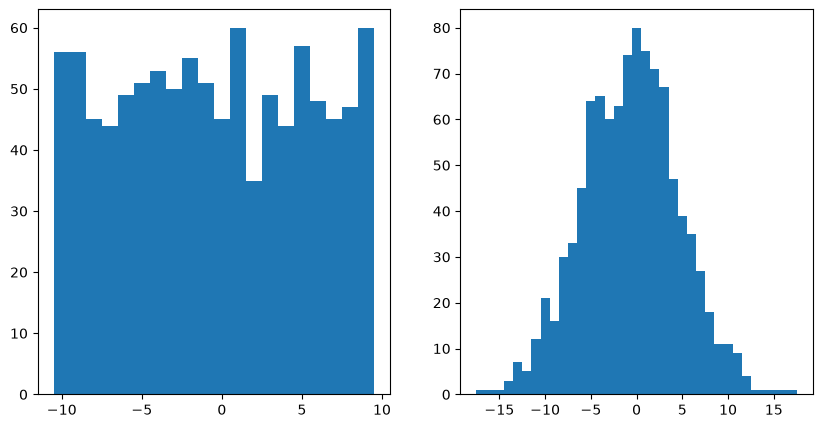

In [32]:
# przyklady
uniform = np.random.uniform(-10,10,1000)
normal = np.random.normal(0,5,1000)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plot_hist(uniform, bucket_size=1)

plt.subplot(1, 2, 2)
plot_hist(normal, bucket_size=1)

In [44]:
# dla danych wielowymiarowych mozemy stworzyc macierz subplot pokazujaca scatter dwoch zbiorow danych 

def subplot_matrix(data:list):
    num_vectors = len(data)
    fig, ax = plt.subplots(num_vectors, num_vectors, figsize = (15,6))
    for i in range(num_vectors):
        for j in range(num_vectors):
            if i == j:
                ax[i,j].annotate('series ' + str(i), (0.5,0.5), xycoords ='axes fraction')
            
            else: ax[i,j].scatter(data[i],data[j])
             


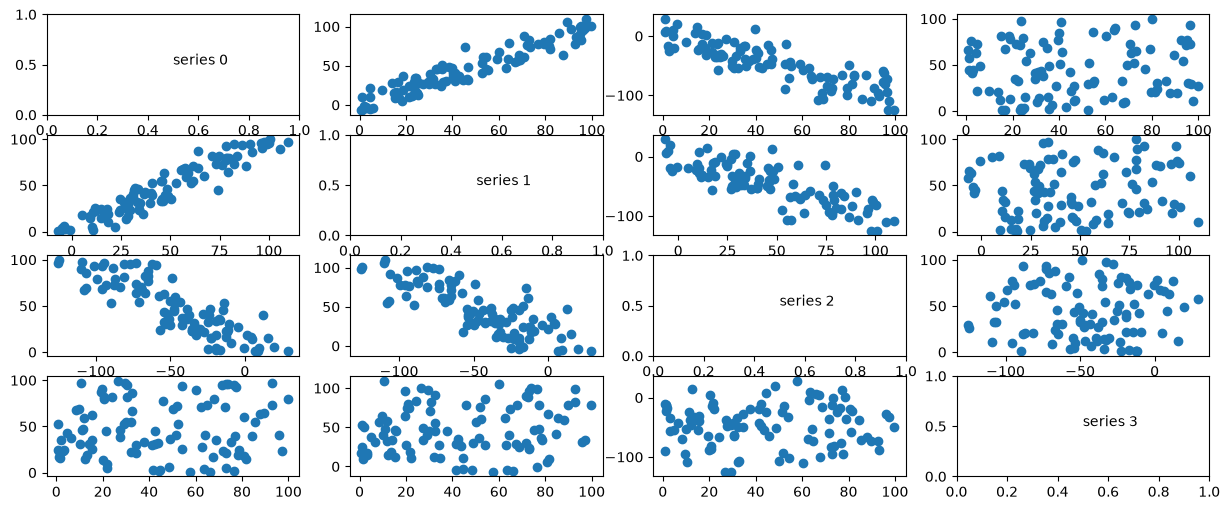

In [45]:
np.random.seed(67)

baza = np.random.rand(100) * 100

seria_0 = baza 
seria_1 = baza + np.random.randn(100) * 10   # Silna korelacja dodatnia z serią 0 (baza + mały szum)
seria_2 = -baza + np.random.randn(100) * 20  # Korelacja ujemna z serią 0 (odwrócona baza + większy szum)
seria_3 = np.random.rand(100) * 100          # Całkowicie losowy szum (brak korelacji z resztą)

zestaw_danych = [seria_0, seria_1, seria_2, seria_3]

subplot_matrix(zestaw_danych)
plt.show()

In [52]:
# named tuples 
from collections import namedtuple

stock_price = namedtuple('price', ['symbol', 'date', 'closing_price'])

portfolio = [
    stock_price('msft', (2021, 11, 2), 106.3),
    stock_price('apl', (2021, 11, 3), 206.3)
]

nowy_rekord = stock_price('goog', (2021, 11, 4), 2800.5)
portfolio.append(nowy_rekord)
portfolio

[price(symbol='msft', date=(2021, 11, 2), closing_price=106.3),
 price(symbol='apl', date=(2021, 11, 3), closing_price=206.3),
 price(symbol='goog', date=(2021, 11, 4), closing_price=2800.5)]

In [153]:
# przewagi i roznice miedzy struktura namedturple a dict
import datetime
from collections import defaultdict
from typing import NamedTuple
class stock_pr(NamedTuple):
    symbol: str
    date: datetime.date
    price: float
    currency:str = 'USD'



portfolio_defaultdict = defaultdict(list) # pozwala w locie dodac nowy klucz i przypisze mu domyslnie wartosc jako tablica
portfolio_dict = {} # zwykly slownik
portfolio_namedturple = stock_pr('AAPL','01-02-2021',123)
portfolio_namedturple = portfolio_namedturple._replace(price = 150)
print(portfolio_namedturple)
print(portfolio_namedturple.price)
try: 
    portfolio_defaultdict['AAPL'].append(10)
    print(portfolio_defaultdict)
except Exception as e:
    print("Wystąpił błąd:", e)
try:
    portfolio_dict['AAPL'].append(10)
    print(portfolio_dict)
except Exception as e:
    print("Wystąpił błąd:", e)

stock_pr(symbol='AAPL', date='01-02-2021', price=150, currency='USD')
150
defaultdict(<class 'list'>, {'AAPL': [10]})
Wystąpił błąd: 'AAPL'


In [105]:
# jak radzic sobie z danymi o innym typie niz chcemy 

from dateutil.parser import parse
import datetime

def parse_row(row):
    symbol, date, closing_price = row
    return stock_price(symbol,
                       date = parse(date).date(),
                       closing_price = float(closing_price)
                       )
stock = parse_row(['msft','2021-04-10', '104'])
stock

price(symbol='msft', date=datetime.date(2021, 4, 10), closing_price=104.0)

In [124]:
# manipulating data
# pobierzemy z interentu ceny na zamknieciu kilku spolek akcyjnych i sprawdzimy najwieksza procentowa zmiane ceny akcji 
import yfinance as yf
import pandas as pd 
apple_stock = yf.Ticker('AAPL')
hist = apple_stock.history(period = '1mo')
hist.reset_index(inplace=True)
hist.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2026-07-20 00:00:00-04:00,333.222613,333.422423,323.401067,326.308563,53468000,0.0,0.0
1,2026-07-21 00:00:00-04:00,322.851568,329.315994,321.942348,327.457581,41338900,0.0,0.0
2,2026-07-22 00:00:00-04:00,327.587466,328.716497,323.061371,325.609192,38755900,0.0,0.0
3,2026-07-23 00:00:00-04:00,321.452790,323.021414,319.074836,321.382843,40840800,0.0,0.0
4,2026-07-24 00:00:00-04:00,321.512728,334.081875,321.342861,332.733032,47489400,0.0,0.0


In [97]:
list(hist[['Date', 'Close']].iloc[0])


[Timestamp('2026-07-20 00:00:00-0400', tz='America/New_York'),
 np.float64(326.3085632324219)]

In [123]:

def make_portfolio(ticker): 
    hist = yf.Ticker(ticker).history(period ='1mo')
    hist.reset_index(inplace=True)
    return[
        parse_row([
            ticker, 
            str(hist['Date'].iloc[i]), 
            str(hist['Close'].iloc[i])
        ]) 
        for i in range(len(hist))
    ]
x = make_portfolio('AAPL')

def pct_change(portfolio: list):
    return [
        (dzisiaj.symbol, dzisiaj.date, ((dzisiaj.closing_price / wczoraj.closing_price) - 1)*100)
        for wczoraj, dzisiaj in zip(portfolio, portfolio[1:])
    ]

najwiekszy_wzrost = max(pct_change(x), key=lambda element: element[2])


max_id = najwiekszy_wzrost[1]       
max_wartosc = najwiekszy_wzrost[2] 

print(f"Największy wzrost był w dniu: {max_id}")
print(f"Wynosił on: {max_wartosc:.2f}%")

Największy wzrost był w dniu: 2026-07-24
Wynosił on: 3.53%


In [ ]:
# problem jednostek (rescaling)
import numpy as np
class Person(NamedTuple):
    name: str
    height_inches: float
    height_cm: float
    weight_lbs: float

tabela_osob = [
    Person('A', 63.0, 160.0, 150.0),
    Person('B', 67.0, 170.2, 160.0),
    Person('C', 70.0, 177.8, 171.0)
]
dane_do_scalowania_cm = np.array([[p.height_cm, p.weight_lbs] for p in tabela_osob])
dane_do_scalowania_inch = np.array([[p.height_inches, p.weight_lbs] for p in tabela_osob])

print('cm: ',
      f'a_b {np.linalg.norm(dane_do_scalowania_cm[0] - dane_do_scalowania_cm[1])}',
      f'a_c {np.linalg.norm(dane_do_scalowania_cm[0] - dane_do_scalowania_cm[2])}',
      f'b_c {np.linalg.norm(dane_do_scalowania_cm[2] - dane_do_scalowania_cm[1])}')

print('inch: ',
      f'a_b {np.linalg.norm(dane_do_scalowania_inch[0] - dane_do_scalowania_inch[1])}',
      f'a_c {np.linalg.norm(dane_do_scalowania_inch[0] - dane_do_scalowania_inch[2])}',
      f'b_c {np.linalg.norm(dane_do_scalowania_inch[2] - dane_do_scalowania_inch[1])}')

print('zmiania jednostek powoduje zmane odlegosci miedzy dwoma recordami w postaci punktow w R2')


cm:  a_b 14.284257068535268 a_c 27.52889391167034 b_c 13.370115930686627
inch:  a_b 10.770329614269007 a_c 22.135943621178654 b_c 11.40175425099138


In [200]:
# przeprowadzamy norlamizacje poprzez sprowadzenie danych aby ich rozklad mial mean = 0 i stdiv = 1

def scale(data):
    return np.mean(data, axis=0), np.std(data, axis=0)

def rescale(data):
    mean, std = scale(data)
    return (data - mean ) / std

dane_po_scalowaniu_cm = rescale(dane_do_scalowania_cm)
dane_po_scalowaniu_inch = rescale(dane_do_scalowania_inch)

print('cm: ',
      f'a_b {np.linalg.norm(dane_po_scalowaniu_cm[0] - dane_po_scalowaniu_cm[1])}')
print('inch: ',
      f'a_b {np.linalg.norm(dane_po_scalowaniu_inch[0] - dane_po_scalowaniu_inch[1])}')
print('po zeskalowaniu nie ma juz problemu z jednostami')

cm:  a_b 1.8209364200867357
inch:  a_b 1.8180931115485108
po zeskalowaniu nie ma juz problemu z jednostami


In [204]:
# tqdm
import tqdm

for i in tqdm.trange(100):
    _ = [np.random.uniform(-1,1) for _ in range(100_000)]

100%|██████████| 100/100 [00:07<00:00, 12.51it/s]


In [238]:
# bardziej zaawansowane uzycie
def primes_pu_to(n):
    primes = [2]
    with tqdm.trange(3,n) as t:
        for i in t:
            i_is_prime = not any(i % p == 0 for p in primes)
            if i_is_prime:
                primes.append(i)
            t.set_description(f'{len(primes)} primes')
    return primes
primes_pu_to(100_000)

9592 primes: 100%|██████████| 99997/99997 [00:25<00:00, 3946.33it/s]


[2,
 3,
 5,
 7,
 11,
 13,
 17,
 19,
 23,
 29,
 31,
 37,
 41,
 43,
 47,
 53,
 59,
 61,
 67,
 71,
 73,
 79,
 83,
 89,
 97,
 101,
 103,
 107,
 109,
 113,
 127,
 131,
 137,
 139,
 149,
 151,
 157,
 163,
 167,
 173,
 179,
 181,
 191,
 193,
 197,
 199,
 211,
 223,
 227,
 229,
 233,
 239,
 241,
 251,
 257,
 263,
 269,
 271,
 277,
 281,
 283,
 293,
 307,
 311,
 313,
 317,
 331,
 337,
 347,
 349,
 353,
 359,
 367,
 373,
 379,
 383,
 389,
 397,
 401,
 409,
 419,
 421,
 431,
 433,
 439,
 443,
 449,
 457,
 461,
 463,
 467,
 479,
 487,
 491,
 499,
 503,
 509,
 521,
 523,
 541,
 547,
 557,
 563,
 569,
 571,
 577,
 587,
 593,
 599,
 601,
 607,
 613,
 617,
 619,
 631,
 641,
 643,
 647,
 653,
 659,
 661,
 673,
 677,
 683,
 691,
 701,
 709,
 719,
 727,
 733,
 739,
 743,
 751,
 757,
 761,
 769,
 773,
 787,
 797,
 809,
 811,
 821,
 823,
 827,
 829,
 839,
 853,
 857,
 859,
 863,
 877,
 881,
 883,
 887,
 907,
 911,
 919,
 929,
 937,
 941,
 947,
 953,
 967,
 971,
 977,
 983,
 991,
 997,
 1009,
 1013,
 1019,


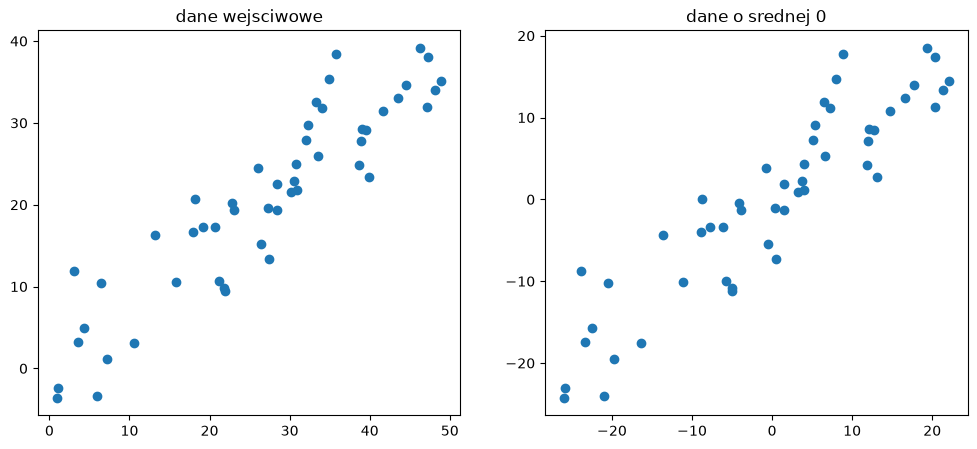

In [234]:
# PCA (principal component analysis)

# krok 1 
#demeaning - srednia kazdego wymiaru ma wynosic 0 
def de_mean(data):
    "liczba wierszy to liczba recordow"
    "liczba kolumn to liczba wymiarow"
    return data - np.mean(data, axis=0)

np.random.seed(0) 
wymiar_x = np.random.uniform(0, 50, 50)
wymiar_y = 0.8 * wymiar_x + np.random.normal(0, 5, 50)
dane_r2 = np.column_stack((wymiar_x, wymiar_y))
dane_de_mean = de_mean(dane_r2)
fig, ax = plt.subplots(1,2, figsize = (12,5))
ax[0].scatter(wymiar_x, wymiar_y)
ax[0].set_title('dane wejsciwowe')
ax[1].scatter(dane_de_mean[:,0], dane_de_mean[:,1])
ax[1].set_title('dane o srednej 0')
plt.show()

In [241]:
# policzenie warancji w kierunku wersowa w 
def direction(w):
    "normalizacja wektora"
    return w/ np.linalg.norm(w)

def directional_variance(data, w):
    return np.sum((data @ direction(w))**2)

# policzenie gradientu dla funkcji variancji w zaleznci od wektora w

def directional_variance_gradient(data, w):
    w_dir = direction(w)
    return [sum(2 * np.dot(v, w_dir) * v[i] for v in data) for i in range(len(w))]


def first_principle_component(data,
                              n,
                              step_size):
    guess = np.random.uniform(-1,1,data.shape[1])
    with tqdm.trange(n) as t:
        for _ in t:
            dv = directional_variance(data, guess)
            gradient = directional_variance_gradient(data, guess)
            guess += np.array(gradient) * step_size # maksymalizujemy funkcje wariancji 
            t.set_description(f'dv: {dv:.3f}')
    return direction(guess)

max_var = first_principle_component(dane_de_mean,1000,0.001)   
max_var 

dv: 15165.588: 100%|██████████| 1000/1000 [00:00<00:00, 2572.97it/s]


array([0.77040891, 0.63755009])

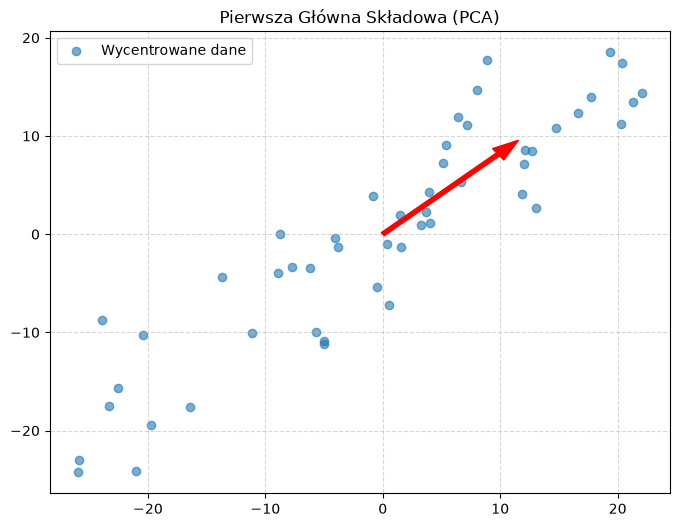

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(dane_de_mean[:, 0], dane_de_mean[:, 1], alpha=0.6, label='Wycentrowane dane')

skala = 15 
początek_x, początek_y = 0, 0 
koniec_x = max_var[0] * skala
koniec_y = max_var[1] * skala

plt.arrow(
    x=początek_x, 
    y=początek_y, 
    dx=koniec_x, 
    dy=koniec_y, 
    color='red', 
    width=0.4,          
    head_width=1.5,     
    length_includes_head=True, 
    zorder=3            
)

ax.set_aspect('equal')

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Pierwsza Główna Składowa (PCA)")
plt.legend()
plt.show()

In [244]:
def remove_projection(data, w):

    rzuty_skalarne = data @ w
    wektory_projekcji = rzuty_skalarne.reshape(-1, 1) * w
    
    return data - wektory_projekcji 

def pca(data, num_components, n=100, step_size=0.001):
    components = []
    current_data = data.copy()
    
    for _ in range(num_components):
        component = first_principle_component(current_data, n, step_size)
        components.append(component)
        
        current_data = remove_projection(current_data, component)
        
    return components


moje_składowe = pca(dane_de_mean, num_components=2, n=100, step_size=0.001)

print("\nPierwsza Główna Składowa:")
print(moje_składowe[0])

print("\nDruga Główna Składowa:")
print(moje_składowe[1])

dv: 653.405: 100%|██████████| 100/100 [00:00<00:00, 3752.65it/s]


Pierwsza Główna Składowa:
[0.77060016 0.63731891]

Druga Główna Składowa:
[-0.63721146  0.77068902]


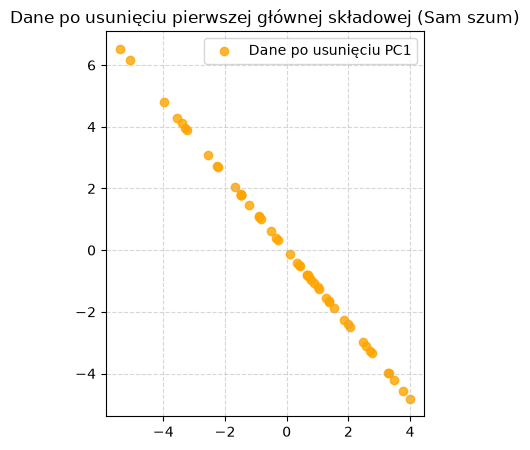

In [249]:
import matplotlib.pyplot as plt

dane_bez_pc1 = remove_projection(dane_de_mean, moje_składowe[0])

fig, ax = plt.subplots(figsize=(16, 5))

ax.scatter(dane_bez_pc1[:, 0], dane_bez_pc1[:, 1], color='orange', alpha=0.8, label='Dane po usunięciu PC1')

ax.set_aspect('equal')

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Dane po usunięciu pierwszej głównej składowej (Sam szum)")
plt.legend()
plt.show()